<a href="https://colab.research.google.com/github/azizbekrakhmonkulov/computer_vision/blob/main/menu_detector_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
print('Menu Detector')

Menu Detector


In [ ]:
# -----------------
# Import Libraries
# -----------------
from google.colab import drive
import torch
import torchvision.transforms as transforms
from torchvision.models import mobilenet_v2
import torch.nn as nn
import torch.optim as optim

from PIL import Image, UnidentifiedImageError
from torch.utils.data import Dataset, DataLoader
import os
import numpy as np


In [ ]:
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Define Dataset Path

DATASET_PATH = '/content/drive/MyDrive/food101_dataset'

print('Dataset_path:', DATASET_PATH)

CUSTOM_CLASS_MAPPING = {
    'hamburger': 'hamburger',
    'hot_dog': 'hot_dog',
    'pizza': 'pizza',
    'kabob': 'kabob',
    'osh': 'osh',
    'manti': 'manti',
    'cheesecake': 'dessert', # lable gropping / class consolidation
    'chocolate_cake': 'dessert', # lable gropping / class consolidation

}

CLASSES = ['hamburger', 'hot_dog', 'pizza', 'kabob', 'osh', 'manti', 'dessert']
CLASS_TO_INDEX = {c: i for i, c in enumerate(CLASSES)}
NUMBER_CLASES = len(CLASSES)

print('Classes:', CLASSES)
print('Class to index:', CLASS_TO_INDEX)
print('Number of classes:', NUMBER_CLASES)

img_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

Dataset_path: /content/drive/MyDrive/food101_dataset
Classes: ['hamburger', 'hot_dog', 'pizza', 'kabob', 'osh', 'manti', 'dessert']
Class to index: {'hamburger': 0, 'hot_dog': 1, 'pizza': 2, 'kabob': 3, 'osh': 4, 'manti': 5, 'dessert': 6}
Number of classes: 7


In [ ]:

# ---------------------------
# Custom Dataset Class
# ---------------------------

from PIL import Image, UnidentifiedImageError
from torch.utils.data import Dataset

class FoodDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        # print('images_length', len(self.images))
        return len(self.images)

    def __getitem__(self, idx):
        img_path = self.images[idx]
        # print('image_path', img_path)

        label = self.labels[idx]
        # print('label', label)

        try:
            image = Image.open(img_path)

            if image.mode == "P" or image.mode == "RGBA":
               image = image.convert("RGBA").convert("RGB")
            else:
               image = image.convert("RGB")
        except (UnidentifiedImageError, OSError):
            print(f"Skipping broken image: {img_path}")
            return self.__getitem__((idx + 1) % len(self.images))

        if self.transform:
            image = self.transform(image)

        return image, label


In [ ]:

# -------------------
# Gather and Split Data
# -------------------

all_images = []

for original_class, mapped_class in CUSTOM_CLASS_MAPPING.items():
    class_path = os.path.join(DATASET_PATH, original_class)
    print('class_path:', class_path)

    if not os.path.exists(class_path):
        print(f"Warning: {class_path} not found")
        continue

    for img in os.listdir(class_path):
        if img.lower().endswith(('.jpg', '.jpeg', '.png')):
            full_path = os.path.join(class_path, img)
            all_images.append(
                (full_path, CLASS_TO_INDEX[mapped_class])
            )

np.random.shuffle(all_images)

split = int(0.8 * len(all_images))

train_data = all_images[:split]
val_data = all_images[split:]

train_images, train_labels = zip(*train_data)
val_images, val_labels = zip(*val_data)

print('all_images:', all_images)

dataset = FoodDataset(train_images, train_labels)
print(len(dataset))

img, lbl = dataset[0]


class_path: /content/drive/MyDrive/food101_dataset/hamburger
class_path: /content/drive/MyDrive/food101_dataset/hot_dog
class_path: /content/drive/MyDrive/food101_dataset/pizza
class_path: /content/drive/MyDrive/food101_dataset/kabob
class_path: /content/drive/MyDrive/food101_dataset/osh
class_path: /content/drive/MyDrive/food101_dataset/manti
class_path: /content/drive/MyDrive/food101_dataset/cheesecake
class_path: /content/drive/MyDrive/food101_dataset/chocolate_cake
all_images: [('/content/drive/MyDrive/food101_dataset/pizza/1512514.jpg', 2), ('/content/drive/MyDrive/food101_dataset/hot_dog/315747.jpg', 1), ('/content/drive/MyDrive/food101_dataset/hot_dog/98515.jpg', 1), ('/content/drive/MyDrive/food101_dataset/cheesecake/1469076.jpg', 6), ('/content/drive/MyDrive/food101_dataset/pizza/714991.jpg', 2), ('/content/drive/MyDrive/food101_dataset/chocolate_cake/1835084.jpg', 6), ('/content/drive/MyDrive/food101_dataset/pizza/269396.jpg', 2), ('/content/drive/MyDrive/food101_dataset/hamb

In [ ]:
train_dataset = FoodDataset(train_images, train_labels, transform=img_transforms)
val_dataset = FoodDataset(val_images, val_labels, transform=img_transforms)

In [ ]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

In [ ]:
# pre-trined model

model = mobilenet_v2(weights='IMAGENET1K_V1')
model.classifier[1] = torch.nn.Linear(model.classifier[1].in_features, NUMBER_CLASES) #fine-tuning

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 125MB/s]


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)
model = model.to(device)

cuda


In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
torch.backends.cudnn.benchmark = True

In [ ]:

# ---------------------------
# Training Loop
# ---------------------------

NUM_EPOCHS = 5
best_accuracy = 0.0

for epoch in range(NUM_EPOCHS):
    model.train()
    running_loss = 0.0

    # Training
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    # Validation
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_acc = 100 * correct / total

    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS}] "
        f"Loss: {running_loss/len(train_loader):.4f}, "
        f"Val Accuracy: {val_acc:.2f}%"
    )

    # Save Best Model
    if val_acc > best_accuracy:
        best_accuracy = val_acc

        torch.save(
            model.state_dict(),
            '/content/menu_detector.pth'
        )

        print("Saved new best model!")



Epoch [1/5] Loss: 0.6071, Val Accuracy: 88.31%
Saved new best model!
Epoch [2/5] Loss: 0.3634, Val Accuracy: 89.88%
Saved new best model!
Epoch [3/5] Loss: 0.3034, Val Accuracy: 83.79%
Epoch [4/5] Loss: 0.2727, Val Accuracy: 88.41%
Epoch [5/5] Loss: 0.1873, Val Accuracy: 89.78%


# **Menu_detector model usage.**

device: cuda
Upload food images:


Saving images (2).jpeg to images (2).jpeg


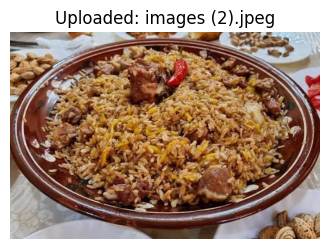

Prediction:
✅ osh: 90.88%
✅ pizza: 6.81%
✅ kabob: 1.20%
✅ dessert: 0.97%


In [17]:

# ---------------------------
# Required Imports
# ---------------------------

import torch
import torchvision.transforms as transforms
from torchvision.models import mobilenet_v2
from PIL import Image
from google.colab import files
import io
import matplotlib.pyplot as plt

# ---------------------------
# Define Semantic Classes
# ---------------------------

CLASSES = ['hamburger', 'hot_dog', 'pizza', 'kabob', 'osh', 'manti', 'dessert']
NUM_CLASSES = len(CLASSES)
CLASS_TO_IDX = {cls: i for i, cls in enumerate(CLASSES)}

# ---------------------------
# Transform for Uploaded Images
# ---------------------------

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ---------------------------
# Load Model
# ---------------------------

model = mobilenet_v2(weights=None)

model.classifier[1] = torch.nn.Linear(
    model.classifier[1].in_features,
    NUM_CLASSES
)

model.load_state_dict(
    torch.load(
        '/content/menu_detector.pth',
        map_location='cpu',
        weights_only=True
    )
)

device = torch.device(
    'cuda' if torch.cuda.is_available() else 'cpu'
)

print('device:', device)

model = model.to(device)
model.eval()

# ---------------------------
# Upload & Predict
# ---------------------------

print("Upload food images:")
uploaded = files.upload()

for image_name in uploaded.keys():
    image = Image.open(
        io.BytesIO(uploaded[image_name])
    ).convert('RGB')

    # Display image
    plt.figure(figsize=(4, 4))
    plt.imshow(image)
    plt.axis('off')
    plt.title(f'Uploaded: {image_name}')
    plt.show()

    # Predict
    image_tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(image_tensor)
        probs = torch.softmax(output, dim=1)[0]
        topk = torch.topk(probs, min(4, NUM_CLASSES))

    print("Prediction:")

    for i in range(topk.indices.size(0)):
        label = CLASSES[topk.indices[i].item()]
        confidence = topk.values[i].item() * 100

        print(f"✅ {label}: {confidence:.2f}%")

